# Fairness Auditing, Demographic Ablation & Leakage Sensitivity (Part 2)

This notebook loads and visualizes the Part 2 outputs generated by:

```bash
python -m src.fairness --task multiclass       # (and --task binary)
python -m src.ablation --task multiclass       # (and --task binary)
python -m src.audit_features --task multiclass # (and --task binary)
```

Switch `TASK` below between `"multiclass"` (3-class, n = 4,424) and `"binary"`
(Dropout vs Graduate, n = 3,630) to inspect either modeling variant.

In [7]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():          # started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
from IPython.display import Image, display

from src import config as C

TASK = "multiclass"          # change to "binary" to inspect Dropout vs Graduate
HIGHLIGHT_MODEL = "XGBoost"
RES_DIR = C.RESULTS_DIR / TASK
print(f"Inspecting Part 2 results for task = '{TASK}' in {RES_DIR}")

Inspecting Part 2 results for task = 'multiclass' in C:\Users\sonan\เดสก์ท็อป\JAIST\Master_Y1\Term 2-1\K417 Co-Creation\student-dropout-prediction\results\multiclass


## 1. Subgroup Fairness Evaluation (Gender & Scholarship Holder)

Metrics are computed strictly from out-of-fold predictions (`oof_predictions.csv`) joined on
`row` to `data/data.csv`:
- **Equal Opportunity (`gap_tpr`)**: difference in Dropout Recall (`Male − Female`, `Non-Scholarship − Scholarship`)
- **Predictive Equality (`gap_fpr`)**: difference in False Positive Rate
- **Demographic Parity (`gap_selection_rate`)**: difference in predicted Dropout rate

A gap closer to `0.0` indicates greater parity across groups.

In [8]:
gaps_path = RES_DIR / "fairness_gaps.csv"
sub_path = RES_DIR / "fairness_subgroups.csv"
inter_path = RES_DIR / "fairness_intersectional.csv"

assert gaps_path.exists(), f"Run `python -m src.fairness --task {TASK}` first."
gaps = pd.read_csv(gaps_path)
sub = pd.read_csv(sub_path)
inter = pd.read_csv(inter_path)

cols_show = [
    "stage", "model", "attribute", "gap_tpr", "gap_tpr_ci_lo", "gap_tpr_ci_hi",
    "gap_fpr", "gap_selection_rate", "gap_roc_auc",
]
print(f"--- Signed Fairness Gaps ({HIGHLIGHT_MODEL}) ---")
display(gaps[gaps["model"] == HIGHLIGHT_MODEL][cols_show].round(4))

print(f"--- Per-Subgroup Rates ({HIGHLIGHT_MODEL}) ---")
display(sub[sub["model"] == HIGHLIGHT_MODEL][
    ["stage", "attribute", "group", "n", "dropout_rate", "tpr", "fpr", "selection_rate", "roc_auc"]
].round(4))

--- Signed Fairness Gaps (XGBoost) ---


,stage,model,attribute,gap_tpr,gap_tpr_ci_lo,gap_tpr_ci_hi,gap_fpr,gap_selection_rate,gap_roc_auc
4,T0,XGBoost,Gender,0.2462,0.1948,0.2963,0.2600,0.3194,-0.0244
5,T0,XGBoost,Scholarship holder,0.4100,0.3345,0.4818,0.2544,0.3617,0.0312
10,T1,XGBoost,Gender,0.0917,0.0444,0.1349,0.0955,0.2201,-0.0025
11,T1,XGBoost,Scholarship holder,0.3449,0.2636,0.4284,0.0930,0.2971,0.0828
16,T2,XGBoost,Gender,0.0713,0.0277,0.1136,0.0838,0.2141,-0.0030
17,T2,XGBoost,Scholarship holder,0.2403,0.1605,0.3259,0.0721,0.2762,0.0503


--- Per-Subgroup Rates (XGBoost) ---


,stage,attribute,group,n,dropout_rate,tpr,fpr,selection_rate,roc_auc
8,T0,Gender,Male,1556,0.4505,0.6976,0.3825,0.5244,0.7282
9,T0,Gender,Female,2868,0.2510,0.4514,0.1224,0.2050,0.7526
10,T0,Scholarship holder,Non-Scholarship,3325,0.3871,0.6115,0.2782,0.4072,0.7273
11,T0,Scholarship holder,Scholarship,1099,0.1219,0.2015,0.0238,0.0455,0.6961
20,T1,Gender,Male,1556,0.4505,0.7917,0.1626,0.4460,0.8957
21,T1,Gender,Female,2868,0.2510,0.7000,0.0670,0.2259,0.8982
22,T1,Scholarship holder,Non-Scholarship,3325,0.3871,0.7778,0.1241,0.3771,0.9051
23,T1,Scholarship holder,Scholarship,1099,0.1219,0.4328,0.0311,0.0801,0.8223
32,T2,Gender,Male,1556,0.4505,0.8060,0.1368,0.4383,0.9123
33,T2,Gender,Female,2868,0.2510,0.7347,0.0531,0.2242,0.9153


fairness_gaps_multiclass.png


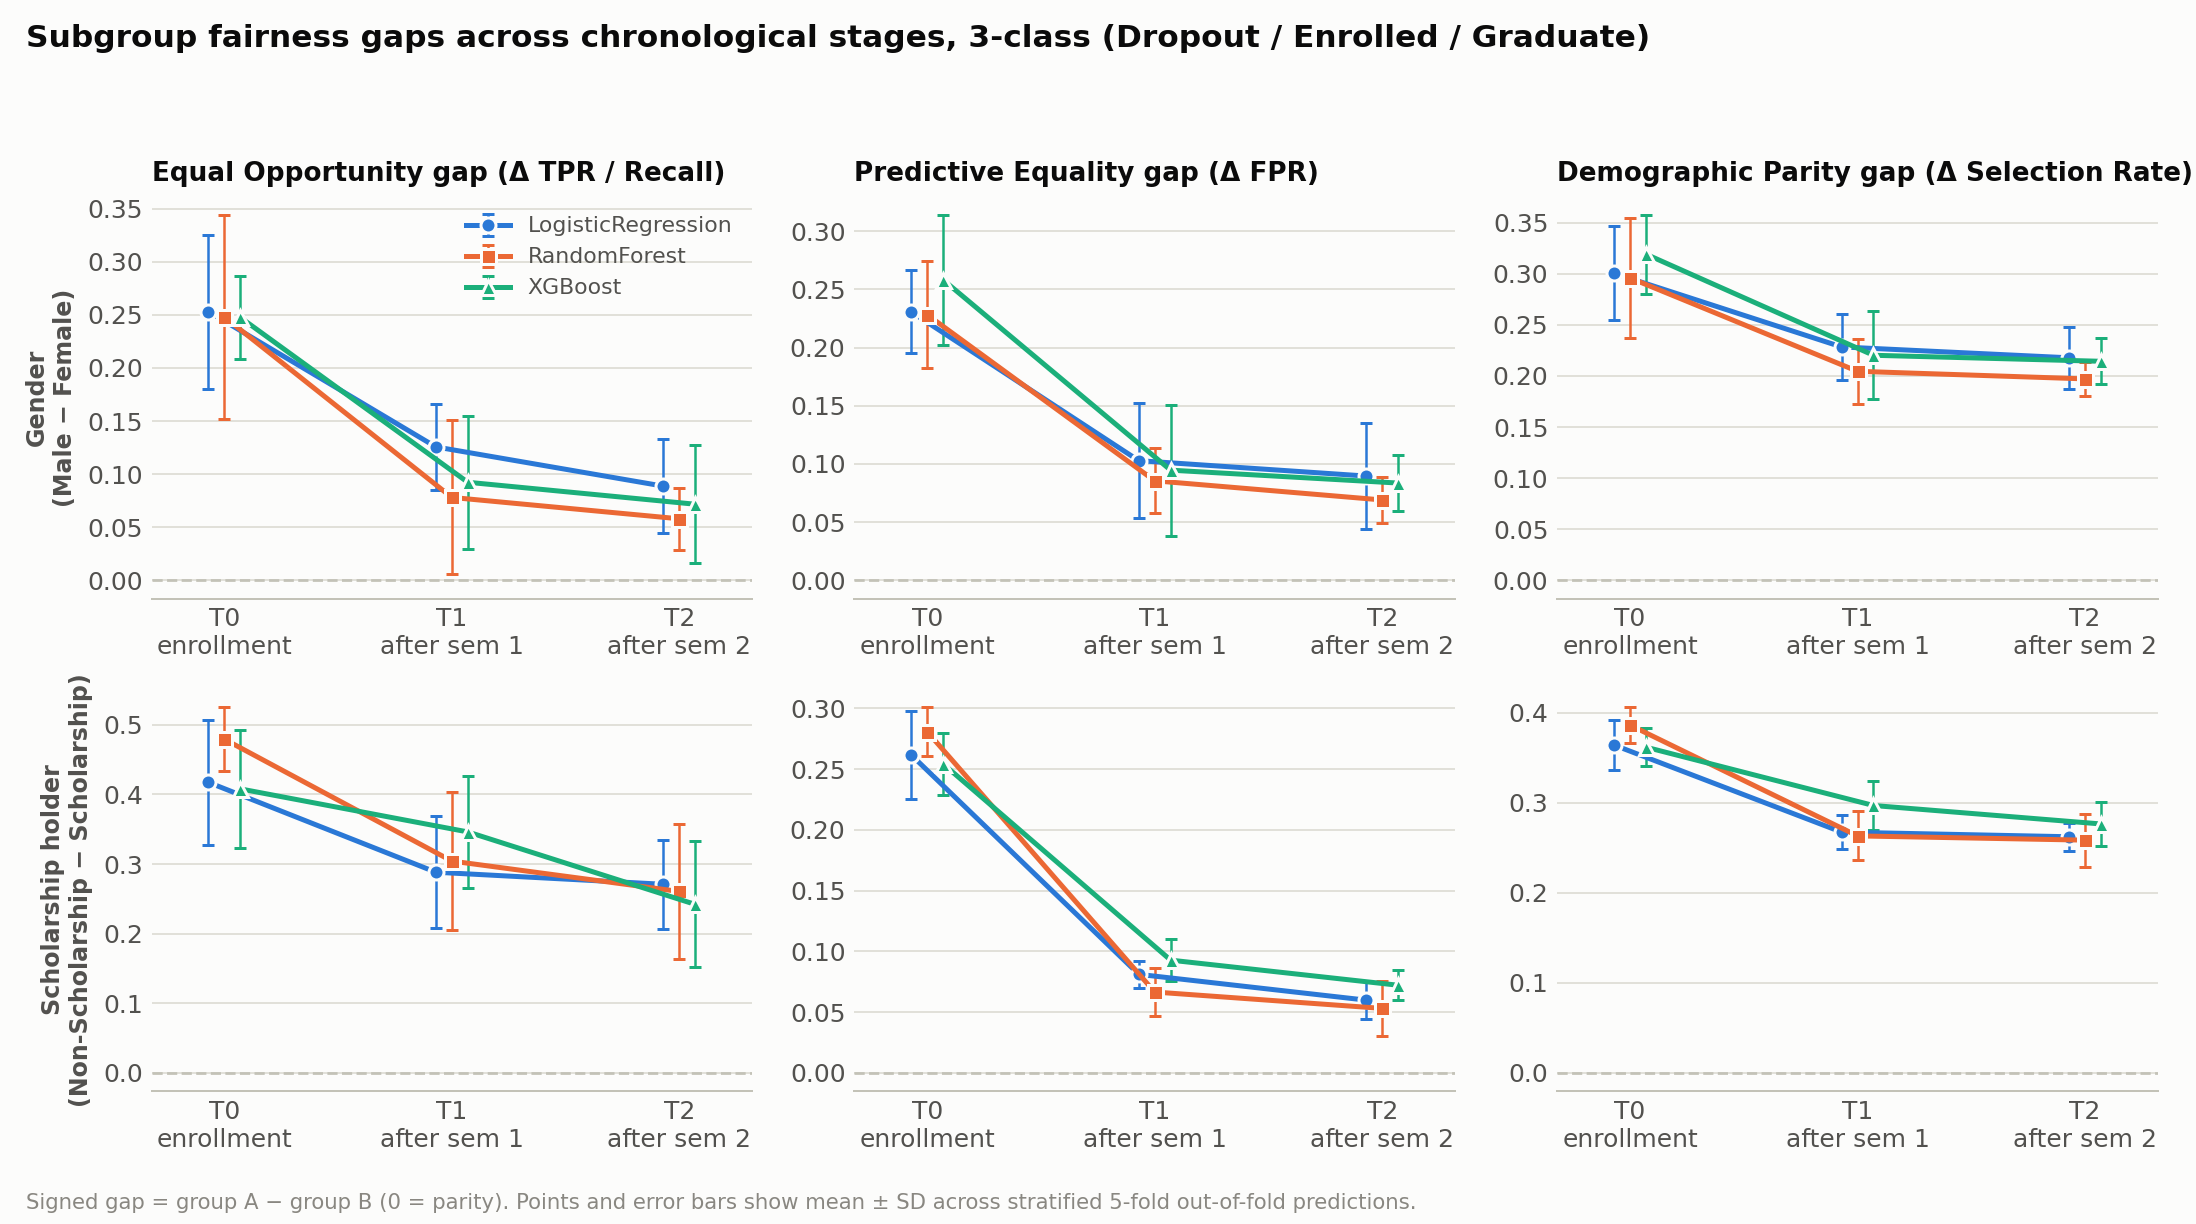

fairness_subgroups_multiclass.png


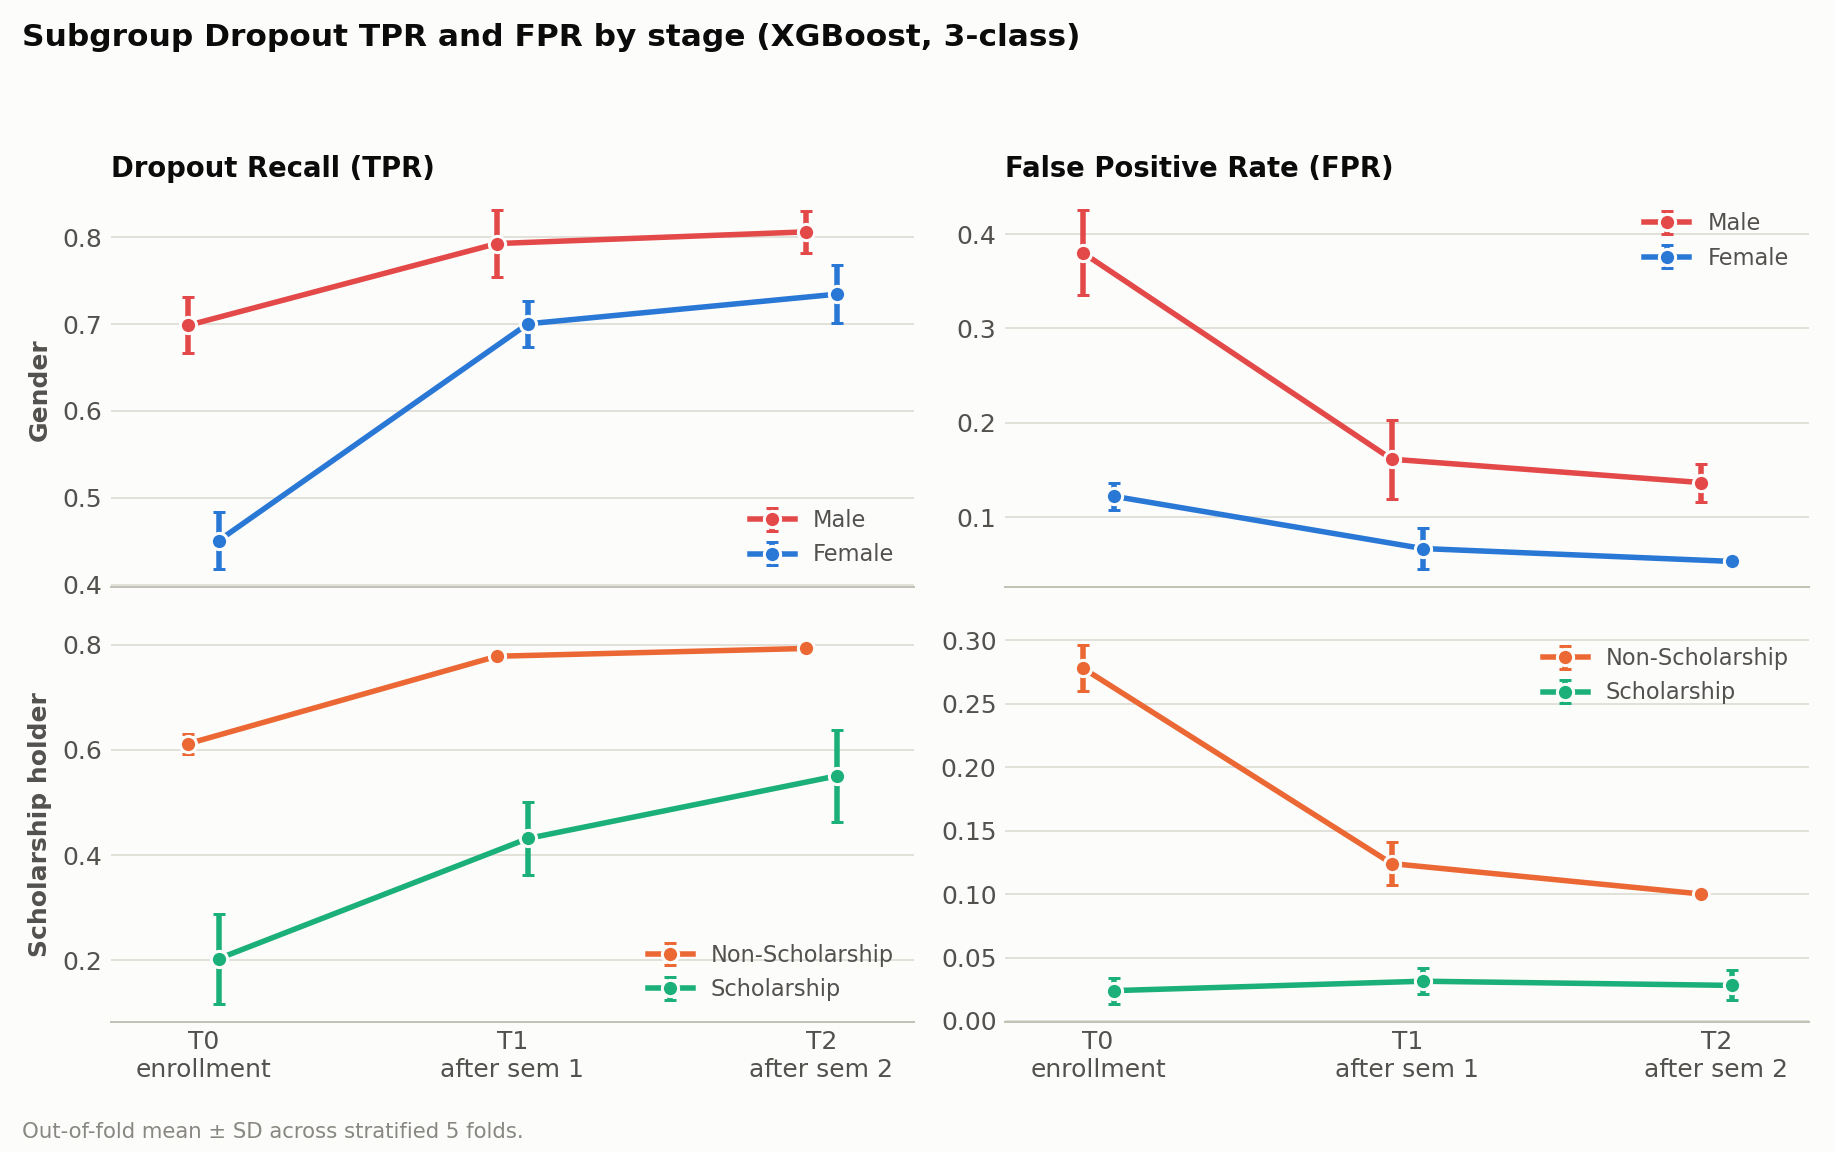

fairness_intersectional_multiclass.png


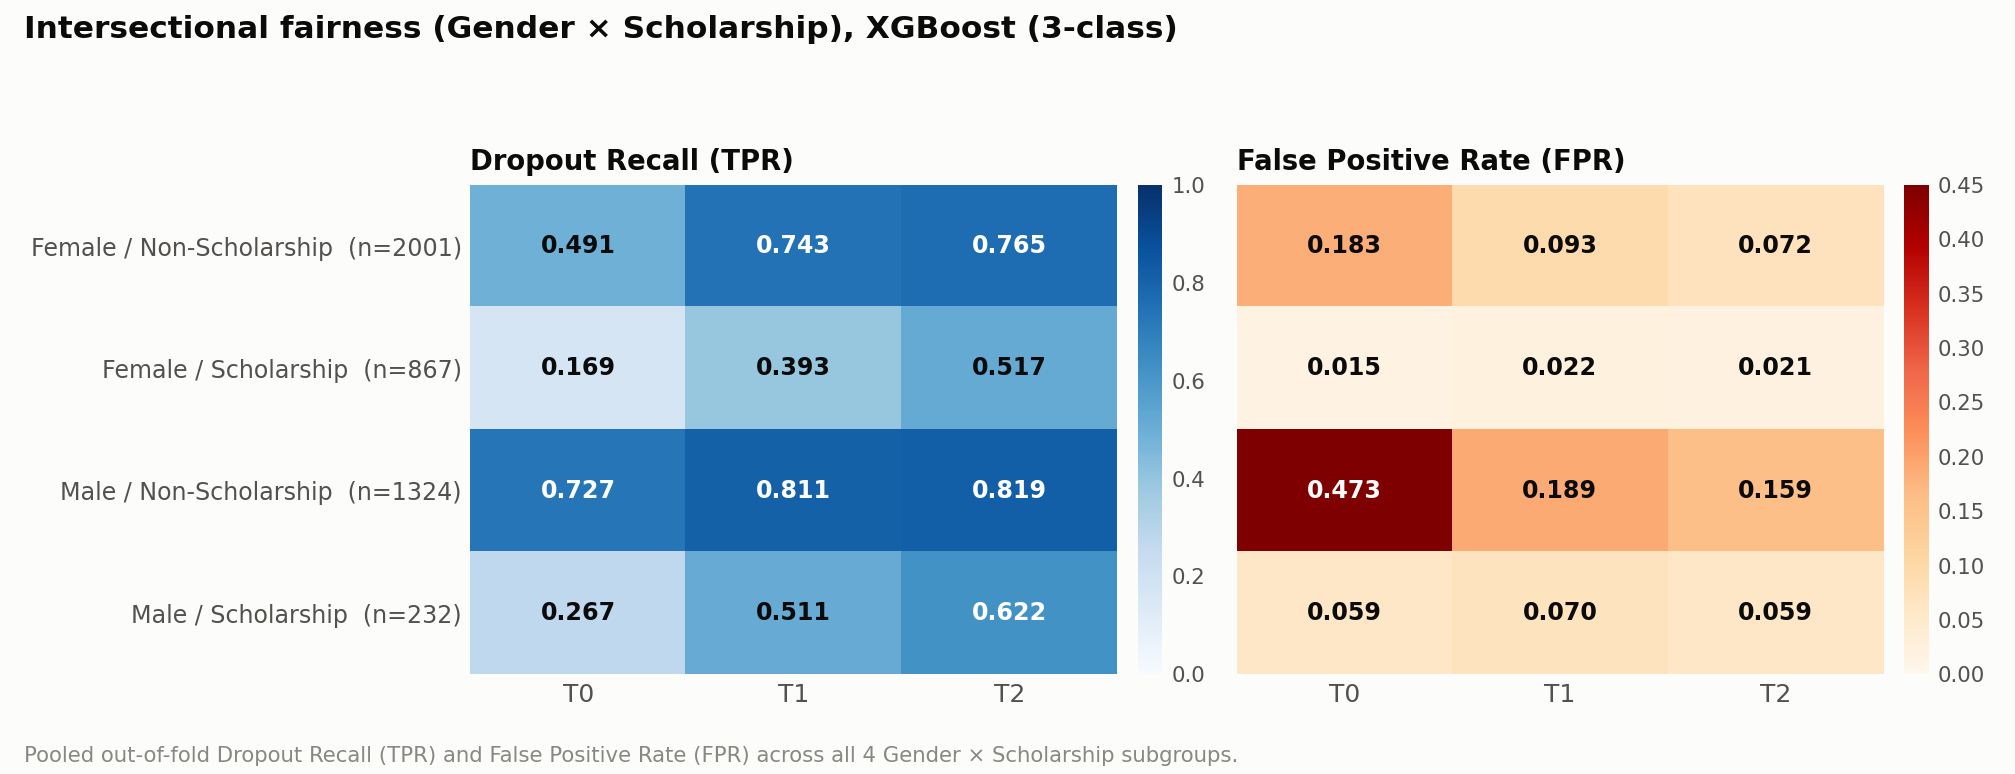

In [9]:
for fig_name in [
    f"fairness_gaps_{TASK}.png",
    f"fairness_subgroups_{TASK}.png",
    f"fairness_intersectional_{TASK}.png",
]:
    p = C.FIGURES_DIR / fig_name
    if p.exists():
        print(fig_name)
        display(Image(filename=str(p)))

## 2. Intersectional Fairness (Gender × Scholarship) & Enrolled Risk Distribution

Checks whether disparities compound across intersections (e.g., Female Scholarship vs
Male Non-Scholarship) and summarizes predicted Dropout risk among the 794 Currently Enrolled students.

In [10]:
print(f"--- Intersectional Table ({HIGHLIGHT_MODEL}) ---")
display(inter[inter["model"] == HIGHLIGHT_MODEL][
    ["stage", "intersectional_group", "n", "dropout_rate", "tpr", "fpr", "roc_auc"]
].round(4))

enr_path = RES_DIR / "enrolled_risk_summary.csv"
if enr_path.exists():
    print("--- Currently Enrolled (n = 794) Risk Summary ---")
    display(pd.read_csv(enr_path).round(4))
else:
    print("enrolled_risk_summary.csv not found (for binary task, ensure models/binary/*.joblib exist).")

--- Intersectional Table (XGBoost) ---


,stage,intersectional_group,n,dropout_rate,tpr,fpr,roc_auc
8,T0,Female / Non-Scholarship,2001,0.3153,0.4913,0.1832,0.7102
9,T0,Female / Scholarship,867,0.1026,0.1685,0.0154,0.6741
10,T0,Male / Non-Scholarship,1324,0.4955,0.7271,0.4730,0.6999
11,T0,Male / Scholarship,232,0.1940,0.2667,0.0588,0.6642
20,T1,Female / Non-Scholarship,2001,0.3153,0.7433,0.0927,0.9013
21,T1,Female / Scholarship,867,0.1026,0.3933,0.0218,0.8178
22,T1,Male / Non-Scholarship,1324,0.4955,0.8110,0.1886,0.8964
23,T1,Male / Scholarship,232,0.1940,0.5111,0.0695,0.8008
32,T2,Female / Non-Scholarship,2001,0.3153,0.7654,0.0715,0.9167
33,T2,Female / Scholarship,867,0.1026,0.5168,0.0206,0.8611


--- Currently Enrolled (n = 794) Risk Summary ---


,task,source,stage,model,n_enrolled,p_dropout_mean,p_dropout_median,p_dropout_q25,p_dropout_q75,pct_pred_dropout,pct_p_ge_050,pct_p_ge_070,mean_p_male,mean_p_female,mean_p_no_scholar,mean_p_scholar
0,multiclass,oof_multiclass,T0,LogisticRegression,794,0.2927,0.2660,0.1554,0.4058,0.2456,0.1272,0.0302,0.3606,0.2498,0.3190,0.1584
1,multiclass,oof_multiclass,T0,RandomForest,794,0.3190,0.2936,0.2192,0.3966,0.2846,0.1184,0.0151,0.3713,0.2860,0.3457,0.1827
2,multiclass,oof_multiclass,T0,XGBoost,794,0.3128,0.2717,0.1415,0.4449,0.2972,0.2078,0.0604,0.3957,0.2606,0.3444,0.1515
3,multiclass,oof_multiclass,T1,LogisticRegression,794,0.2469,0.1754,0.0751,0.3483,0.1826,0.1436,0.0604,0.2946,0.2167,0.2571,0.1946
4,multiclass,oof_multiclass,T1,RandomForest,794,0.2836,0.2326,0.1377,0.3808,0.2015,0.1335,0.0466,0.3192,0.2611,0.2939,0.2307
5,multiclass,oof_multiclass,T1,XGBoost,794,0.2858,0.2118,0.0909,0.4050,0.2431,0.1965,0.0882,0.3357,0.2543,0.3002,0.2122
6,multiclass,oof_multiclass,T2,LogisticRegression,794,0.2346,0.1601,0.0742,0.3328,0.1562,0.1234,0.0529,0.2829,0.2042,0.2459,0.1773
7,multiclass,oof_multiclass,T2,RandomForest,794,0.2714,0.2213,0.1296,0.3516,0.1600,0.1196,0.0554,0.3108,0.2466,0.2834,0.2102
8,multiclass,oof_multiclass,T2,XGBoost,794,0.2712,0.1881,0.0662,0.4044,0.2116,0.1788,0.0844,0.3246,0.2375,0.2892,0.1793


## 3. Demographic Ablation Study (Accuracy–Fairness Trade-Off)

Compares four feature sets on identical nested 5-fold CV splits (`SEED = 42`):
- `full`: Part 1 baseline
- `no_sensitive`: drops `Gender` and `Scholarship holder`
- `no_demographic`: drops all 7 personal demographic attributes
- `no_demo_socio`: drops all 12 personal demographic + socioeconomic attributes

--- Predictive Performance Delta vs Full (XGBoost) ---


,variant,stage,n_features,f1_macro_mean,delta_f1_macro_mean,dropout_roc_auc_mean,delta_dropout_roc_auc_mean,dropout_recall_mean
2,full,T0,22,0.5211,0.0000,0.7658,0.0000,0.5729
5,full,T1,31,0.6640,0.0000,0.9058,0.0000,0.7452
8,full,T2,39,0.7051,0.0000,0.9249,0.0000,0.7699
11,no_sensitive,T0,20,0.4951,-0.0260,0.7465,-0.0193,0.5468
14,no_sensitive,T1,29,0.6679,0.0038,0.9022,-0.0036,0.7403
17,no_sensitive,T2,37,0.6960,-0.0090,0.9251,0.0001,0.7600
20,no_demographic,T0,15,0.5117,-0.0094,0.7564,-0.0094,0.5447
23,no_demographic,T1,24,0.6718,0.0077,0.9042,-0.0016,0.7495
26,no_demographic,T2,32,0.7084,0.0033,0.9250,0.0001,0.7692
29,no_demo_socio,T0,10,0.4686,-0.0525,0.7054,-0.0604,0.4962


--- Fairness Gaps Across Ablation Variants (XGBoost) ---


,variant,stage,attribute,gap_tpr,gap_fpr,gap_selection_rate
4,full,T0,Gender,0.2462,0.2600,0.3194
5,full,T0,Scholarship holder,0.4100,0.2544,0.3617
10,full,T1,Gender,0.0917,0.0955,0.2201
11,full,T1,Scholarship holder,0.3449,0.0930,0.2971
16,full,T2,Gender,0.0713,0.0838,0.2141
17,full,T2,Scholarship holder,0.2403,0.0721,0.2762
22,no_sensitive,T0,Gender,0.1343,0.1467,0.2065
23,no_sensitive,T0,Scholarship holder,0.1506,0.1140,0.2059
28,no_sensitive,T1,Gender,0.0508,0.0565,0.1808
29,no_sensitive,T1,Scholarship holder,0.2901,0.0701,0.2692


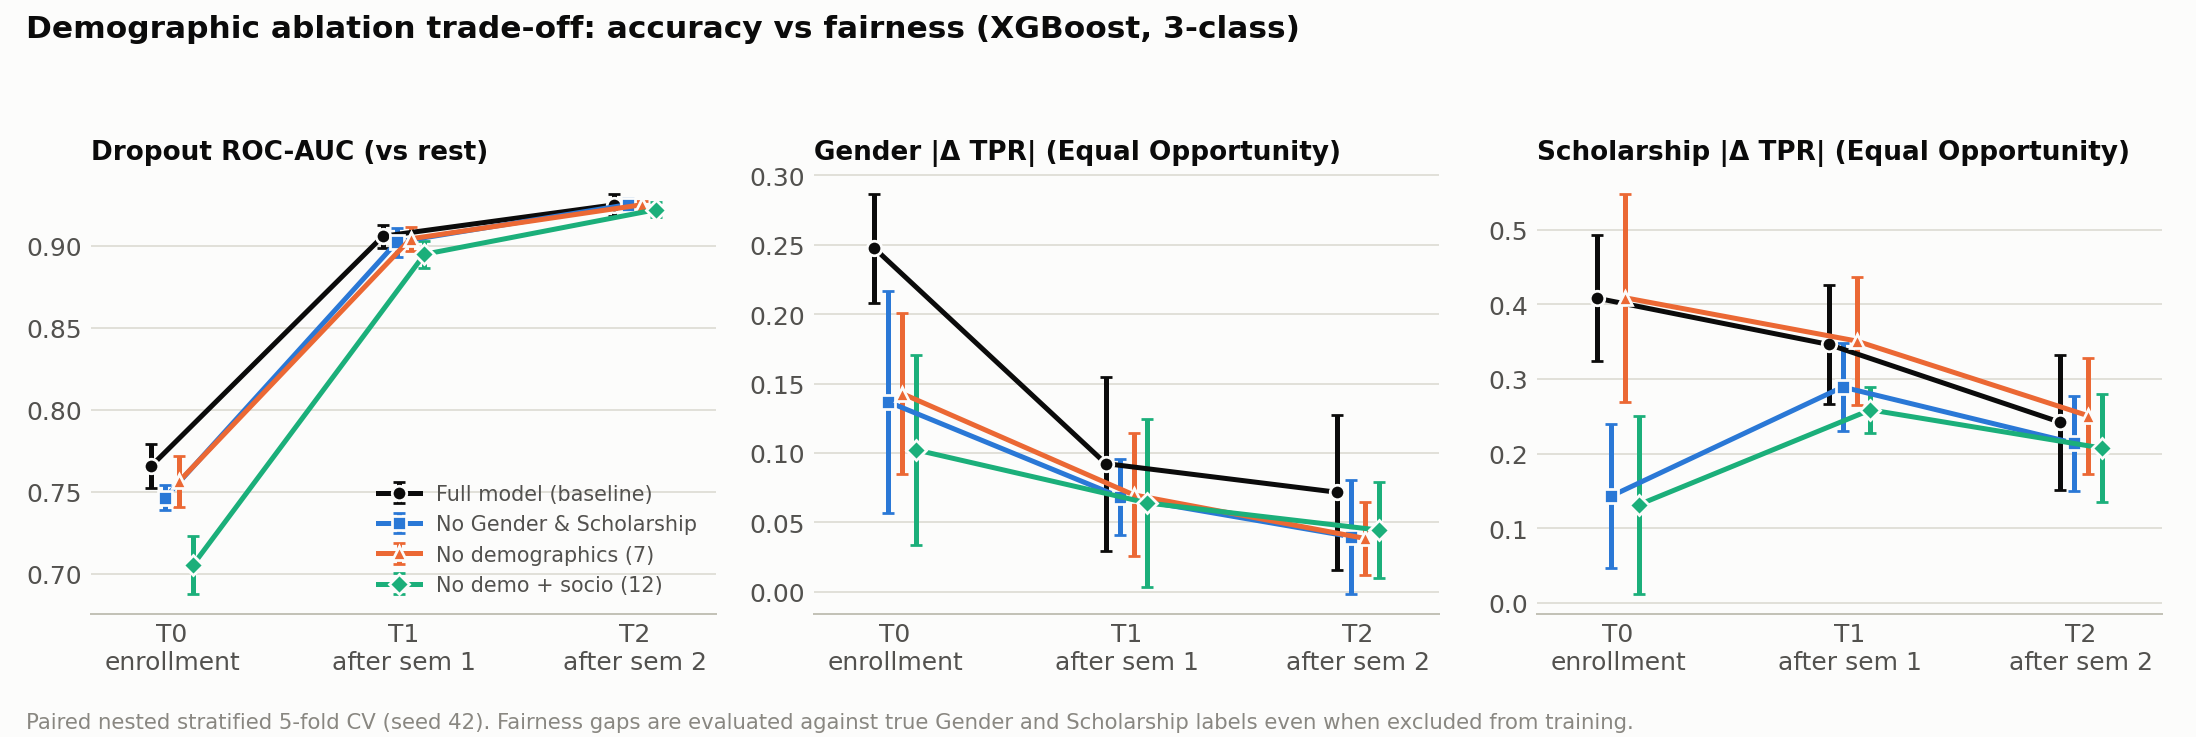

In [11]:
ab_summ_path = RES_DIR / "ablation_summary.csv"
ab_gaps_path = RES_DIR / "ablation_fairness_gaps.csv"

if ab_summ_path.exists() and ab_gaps_path.exists():
    ab_summ = pd.read_csv(ab_summ_path)
    ab_gaps = pd.read_csv(ab_gaps_path)

    print(f"--- Predictive Performance Delta vs Full ({HIGHLIGHT_MODEL}) ---")
    display(ab_summ[ab_summ["model"] == HIGHLIGHT_MODEL][
        ["variant", "stage", "n_features", "f1_macro_mean", "delta_f1_macro_mean",
         "dropout_roc_auc_mean", "delta_dropout_roc_auc_mean", "dropout_recall_mean"]
    ].round(4))

    print(f"--- Fairness Gaps Across Ablation Variants ({HIGHLIGHT_MODEL}) ---")
    display(ab_gaps[ab_gaps["model"] == HIGHLIGHT_MODEL][
        ["variant", "stage", "attribute", "gap_tpr", "gap_fpr", "gap_selection_rate"]
    ].round(4))

    fig_p = C.FIGURES_DIR / f"ablation_tradeoff_{TASK}.png"
    if fig_p.exists():
        display(Image(filename=str(fig_p)))
else:
    print(f"Run `python -m src.ablation --task {TASK}` to generate ablation results.")

## 4. Feature Engineering & Financial Leakage Sensitivity Audit

Evaluates:
1. **`ratio_flagged`**: adds binary flags for `enrolled == 0` (Course 171, n = 180) so `Approval ratio = 0` is disambiguated from failing all enrolled courses.
2. **`no_financial_flags`**: removes `Debtor` and `Tuition fees up to date` at T1/T2 to test robustness without potentially retrospective fee signals.

--- Sensitivity Summary (T1 & T2) ---


,experiment,stage,model,n_features,f1_macro_mean,delta_f1_macro_mean,dropout_roc_auc_mean,delta_dropout_roc_auc_mean
0,baseline,T1,LogisticRegression,31,0.6726,0.0000,0.9003,0.0000
1,baseline,T1,RandomForest,31,0.6844,0.0000,0.9008,0.0000
2,baseline,T1,XGBoost,31,0.6640,0.0000,0.9058,0.0000
3,baseline,T2,LogisticRegression,39,0.7103,0.0000,0.9184,0.0000
4,baseline,T2,RandomForest,39,0.7213,0.0000,0.9206,0.0000
5,baseline,T2,XGBoost,39,0.7051,0.0000,0.9249,0.0000
6,ratio_flagged,T1,LogisticRegression,32,0.6829,0.0104,0.9015,0.0011
7,ratio_flagged,T1,RandomForest,32,0.6804,-0.0040,0.8987,-0.0021
8,ratio_flagged,T1,XGBoost,32,0.6758,0.0118,0.9024,-0.0033
9,ratio_flagged,T2,LogisticRegression,42,0.7140,0.0038,0.9163,-0.0021


--- Impact on Zero-Enrolled (n=180) vs Failed-All (n=538) Subgroups ---


,experiment,stage,model,enrollment_group,n,actual_dropout_rate,predicted_dropout_rate,dropout_recall,dropout_f1,dropout_roc_auc,brier
0,baseline,T1,LogisticRegression,No units enrolled (n=180),180,0.4278,0.5611,0.7662,0.6629,0.7347,0.2036
1,baseline,T1,LogisticRegression,"Enrolled >0, Approved =0 (n=538)",538,0.9164,0.9405,0.9676,0.9550,0.8759,0.0648
2,baseline,T1,RandomForest,No units enrolled (n=180),180,0.4278,0.6556,0.8182,0.6462,0.7116,0.2140
3,baseline,T1,RandomForest,"Enrolled >0, Approved =0 (n=538)",538,0.9164,0.9944,1.0000,0.9591,0.8294,0.0675
4,baseline,T1,XGBoost,No units enrolled (n=180),180,0.4278,0.5222,0.6753,0.6082,0.7248,0.2114
5,baseline,T1,XGBoost,"Enrolled >0, Approved =0 (n=538)",538,0.9164,0.9777,0.9899,0.9578,0.8704,0.0603
6,baseline,T2,LogisticRegression,No units enrolled (n=180),180,0.4278,0.5500,0.7273,0.6364,0.7230,0.2085
7,baseline,T2,LogisticRegression,"Enrolled >0, Approved =0 (n=538)",538,0.9164,0.9312,0.9676,0.9598,0.8983,0.0568
8,baseline,T2,RandomForest,No units enrolled (n=180),180,0.4278,0.6056,0.7662,0.6344,0.6849,0.2192
9,baseline,T2,RandomForest,"Enrolled >0, Approved =0 (n=538)",538,0.9164,0.9591,0.9878,0.9653,0.8566,0.0565


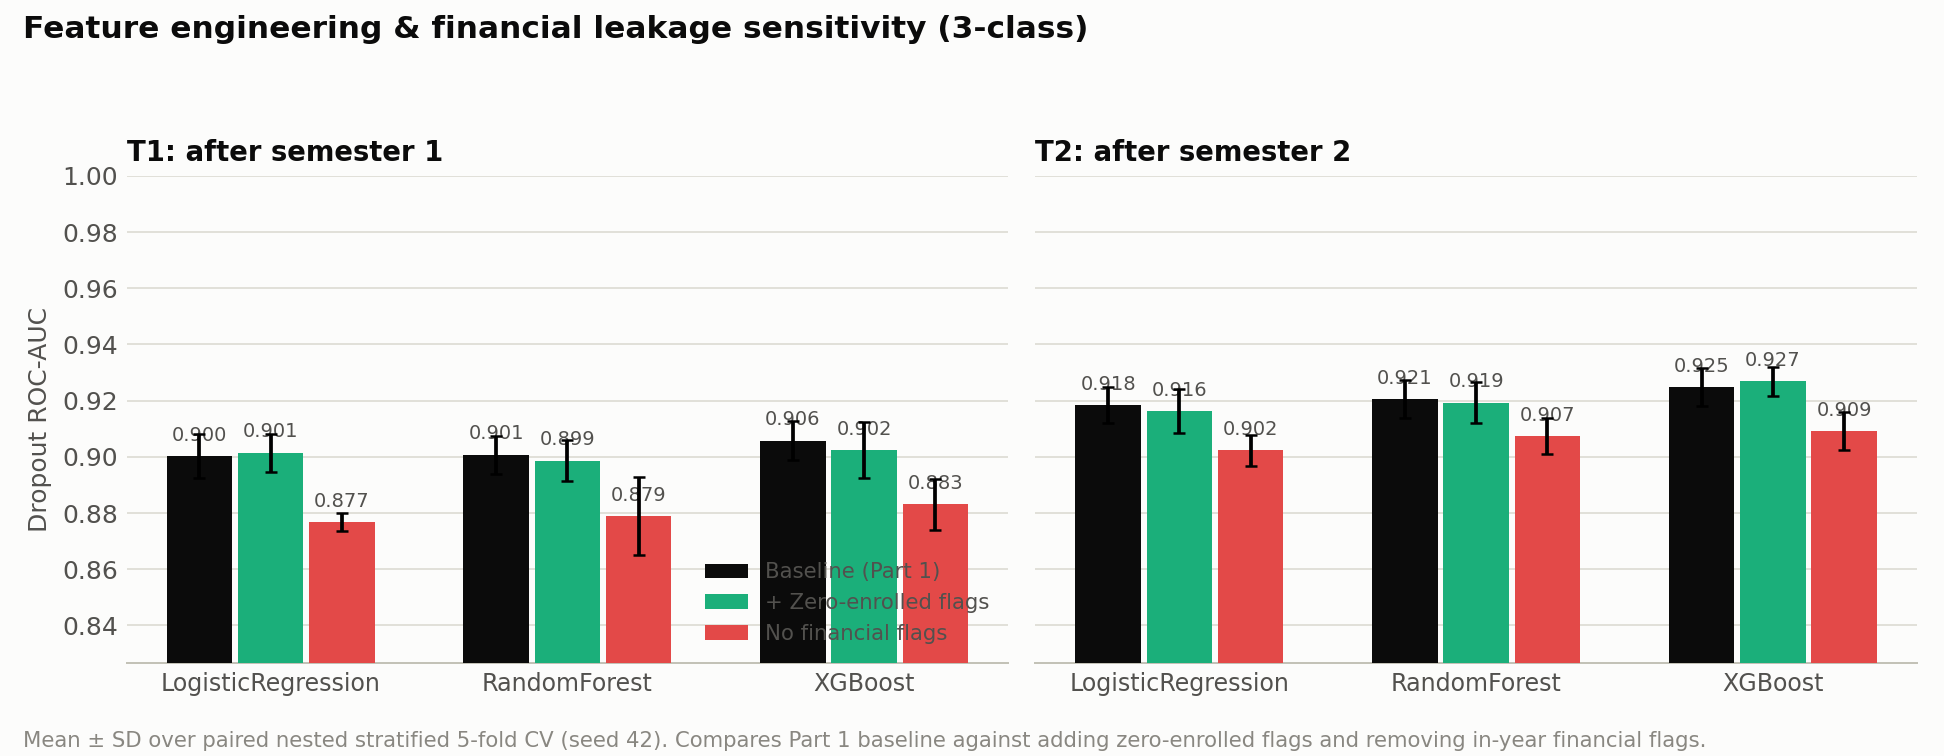

In [12]:
audit_summ_path = RES_DIR / "audit_summary.csv"
zero_sub_path = RES_DIR / "audit_zero_enrolled_subgroup.csv"

if audit_summ_path.exists():
    audit_summ = pd.read_csv(audit_summ_path)
    print("--- Sensitivity Summary (T1 & T2) ---")
    display(audit_summ[
        ["experiment", "stage", "model", "n_features", "f1_macro_mean",
         "delta_f1_macro_mean", "dropout_roc_auc_mean", "delta_dropout_roc_auc_mean"]
    ].round(4))

    if zero_sub_path.exists():
        print("--- Impact on Zero-Enrolled (n=180) vs Failed-All (n=538) Subgroups ---")
        display(pd.read_csv(zero_sub_path).round(4))

    fig_p = C.FIGURES_DIR / f"audit_sensitivity_{TASK}.png"
    if fig_p.exists():
        display(Image(filename=str(fig_p)))
else:
    print(f"Run `python -m src.audit_features --task {TASK}` to generate sensitivity audit results.")